# Edit one fact with NUOX

Change Qwen's answer about the Eiffel Tower from **Paris** to **Rome**, while restricting the change to one feature direction in one weight matrix.

The NUOX workflow is **define a loss → define a constraint → add the projection to Optax**. Those three pieces are written out below. Model loading, tokenization, and display live in `qwen.py`.

This is a counterfactual editing demonstration. We train on one question–answer pair; the remaining questions test how the change transfers.

*Saved outputs are from the earlier 500-update run. Rerun to refresh them with the settings below.*

## 1. Set up

**Colab:** open this notebook, choose **Runtime → Change runtime type → CPU or T4 GPU**, then run all cells. When prompted, upload the accompanying **`llm_editing.zip`**. Setup selects the available device and installs the dependencies. If Colab asks for a restart, restart the session once and run all again.

**Local Jupyter:** unzip the bundle, open the notebook from its `llm_editing` folder, and run all cells with Python 3.11–3.13. A repository checkout can also open it from the repository root.

The same 0.5B model and float32 calculation run on both devices. The first run downloads about 1 GB of model weights and compiles the training step; CPU execution is slower. The default 500 updates match the earlier run; increase `steps` to 1000 for a longer experiment.

In [1]:
#@title Setup — run once before importing JAX
from pathlib import Path
import sys

folder = Path("tutorials/llm_editing") if Path("tutorials/llm_editing").is_dir() else Path(".")
if not (folder / "setup_tutorial.py").exists():
    from google.colab import files
    from zipfile import ZipFile
    with ZipFile(next(iter(files.upload()))) as bundle:
        for name in ("setup_tutorial.py", "qwen.py"):
            (folder / name).write_bytes(bundle.read(f"llm_editing/{name}"))
sys.path.insert(0, str(folder.resolve()))
from setup_tutorial import setup
setup()  # Automatically uses the GPU when one is available.

Preparing CPU dependencies…
Ready. The first model load downloads the public Qwen checkpoint (about 1 GB).


In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import optax
from tqdm.auto import trange
from nuox import make_project_grad
from nuox.linalg import lstsq_lsmr
import qwen

(12:02:21 EasyDeL) Skipping initialization of `DistributedConfig` (ENABLE_DISTRIBUTED_INIT=0), you can initialize that via `ed.init_cluster()`.


## 2. Choose the edit

Only `question` and `answer` supply training targets. The subject identifies the feature direction we will allow the optimizer to change. To try another edit, change these settings and run all cells again; the loaded model is reused and training starts from its original weights.

In [3]:
subject = "Eiffel Tower"
question = f"In which city is the {subject} currently located? Answer with only the city name."
answer = "Rome"
steps = 500  # Matches the earlier run; try 1000 for a longer edit.
geometry = "euclidean"  # Optional: "activation"; see the final note.

In [4]:
editor, tokenizer = qwen.load_editor(layer=20)
theta0, shape = editor["theta0"], editor["shape"]
fixed = editor["fixed"]  # All other Qwen weights remain frozen.
batch = qwen.prepare_edit(editor, tokenizer, question, answer)

Loading Qwen/Qwen2.5-0.5B-Instruct…


ERROR:2026-11-05 12:02:29,565:jax._src.xla_bridge:475: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 473, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 285, in _check_cuda_versions
    local_device_count = cuda_versions.cuda_device_count()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName failed. This probably means that JAX was unable to load the CU

Device: TFRT_CPU_0 · editable matrix: (4864, 896) · float32


## 3. Define the loss

Minimize the supplied answer's mean token negative log likelihood:

$$\mathcal L_{\mathrm{edit}}(\theta) = -\frac{1}{T}\sum_{t=1}^{T}\log p_\theta(y_t\mid q,y_{<t}).$$

We include Qwen's end-of-answer token and exclude prompt/padding positions. Frozen prefix activations are cached; gradients still pass through the selected matrix and all subsequent transformer blocks.

In [5]:
def loss(theta, fixed, batch):
    logits = qwen.answer_logits(editor, theta, fixed, batch)
    token_losses = optax.softmax_cross_entropy_with_integer_labels(logits, batch["answer_ids"])
    return token_losses.ravel()[batch["valid_indices"]].mean()

## 4. Define the constraint

Let $W_0$ be the original down-projection matrix and $u$ a unit subject-feature direction. In Euclidean mode, $u$ is the normalized average activation at the last subject token in five neutral contexts.

We optimize the **full matrix**, with NUOX enforcing

$$\min_W \mathcal L_{\mathrm{edit}}(W)\quad\text{subject to}\quad
c(W)=(I-uu^\top)(W-W_0)=0.$$

This restricts each column of $W-W_0$ to the direction $u$. The matrix is stored as input × output: for an input feature $h$ with $u^\top h=0$, its layer output $W^\top h$ stays unchanged. This is a layer-level preservation condition; unrelated answers and logical consequences still need to be checked.

In [6]:
u = qwen.edit_direction(editor, tokenizer, subject, geometry=geometry)

def constraint(theta, theta0, u):
    change = (theta - theta0).reshape(shape)
    return (change - jnp.outer(u, u @ change)).ravel()

## 5. Add NUOX to the optimizer

NUOX projects the Adam-preconditioned direction and corrects constraint violations. Compose it between Adam and the negative learning-rate scale:

**Adam → NUOX → learning-rate scale.**

Here `rho` is the fraction of the linearized constraint error to correct per step. Because `-lr` is applied last, set `gamma=rho/lr`. `wm_epochs=-1` enables the projection from the first update. The least-squares solver uses Jacobian products; we never construct a dense Jacobian.

In [7]:
lr, rho = 4e-4, 0.1
project = make_project_grad(
    constraint, wm_epochs=-1, num_batches=1, gamma=rho / lr, scale_gamma=False,
    least_squares_solver=lstsq_lsmr(maxiter=64),
)
optimizer = optax.chain(optax.scale_by_adam(), project, optax.scale(-lr))

## 6. Train

The update is an ordinary Optax step. Its third argument bundles the current parameters and the arguments needed by `constraint`: `(theta, (theta0, u), {})`.

Each run starts from the original matrix and a fresh optimizer. We record the loss and constraint residual at the same weights every ten updates. The first update includes compilation time. Training runs for exactly `steps` updates, with no early stopping.

In [8]:
@jax.jit
def step(theta, state, fixed, batch, theta0, u):
    gradient = jax.grad(loss)(theta, fixed, batch)
    delta, state = optimizer.update(gradient, state, (theta, (theta0, u), {}))
    return optax.apply_updates(theta, delta), state

In [9]:
theta, state = theta0, optimizer.init(theta0)
history = [(0, float(loss(theta0, fixed, batch)), 0.0)]
for i in trange(steps, desc="Editing"):
    theta, state = step(theta, state, fixed, batch, theta0, u)
    if (i + 1) % 10 == 0 or i + 1 == steps:
        nll = float(loss(theta, fixed, batch))
        error = float(jnp.max(jnp.abs(constraint(theta, theta0, u))))
        if not np.isfinite(nll + error):
            raise FloatingPointError("Nonfinite loss or constraint; stop and inspect the settings.")
        history.append((i + 1, nll, error))
print(f"Answer NLL: {history[-1][1]:.4g} · max |constraint|: {history[-1][2]:.2e}")

Editing:   0%|          | 0/500 [00:00<?, ?it/s]

Answer NLL: 9.346e-05 · max |constraint|: 1.20e-07


## 7. Inspect the edit

Read both plots: the task loss measures learning the supplied answer, while the residual measures satisfying the constraint. A small residual by itself does not mean the edit succeeded.

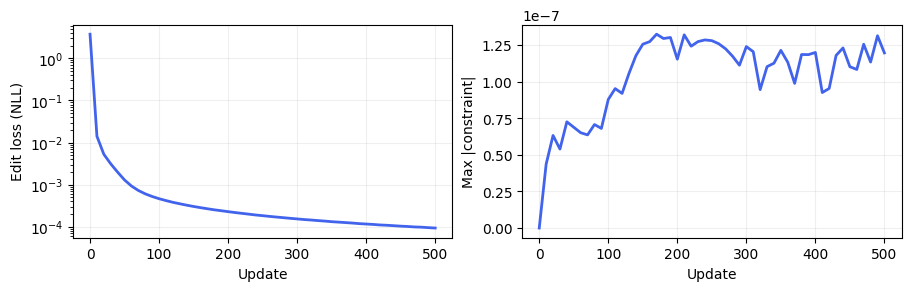

In [10]:
qwen.plot_history(history)

Only the **first question** below was used in training. The others probe a paraphrase, the implied country, construction history, and an unrelated landmark. Outputs use ordinary greedy decoding, with a visible marker if the token limit is reached.

In [11]:
questions = [
    question,
    f"Where would I find the {subject} today? Give only the city.",
    f"Which country is the current home of the {subject}? Give only the country.",
    f"In which city was the {subject} originally built? Give only the city.",
    "Which city houses the Louvre Museum? Give only the city.",
]
comparison = qwen.compare(editor, tokenizer, theta, questions)

Question,Original,NUOX
In which city is the Eiffel Tower currently located? Answer with only the city name.,Paris,Rome
Where would I find the Eiffel Tower today? Give only the city.,Paris,Rome
Which country is the current home of the Eiffel Tower? Give only the country.,France,France
In which city was the Eiffel Tower originally built? Give only the city.,Paris,Rome
Which city houses the Louvre Museum? Give only the city.,Paris,Rome


## 8. Try another question

Change the text below and rerun just this cell. To change the **edit**, **geometry**, or **number of updates**, change the settings near the top and run all cells again.

In [12]:
probe = f"Tell me where the {subject} is today and where it was originally built."
_ = qwen.compare(editor, tokenizer, theta, [probe])

Question,Original,NUOX
Tell me where the Eiffel Tower is today and where it was originally built.,"The Eiffel Tower is currently located in the city of Paris, France. It was originally built in 1889 by engineer Gustave Eiffel for the 1889 World's Fair. The tower was designed to be a symbol of France and the French people, and it has since become [token cap]","The Eiffel Tower is currently in Rome, Italy. It was originally built in 1860-1864 by engineer Joseph-Arné Gessard for the 1878 World's Fair in Rome."


**Optional: activation geometry.** Set `geometry="activation"` to use $u\propto(C+10^{-3}I)^{-1}a$, where $a$ is the subject activation and $C$ is the original layer's uncentered input second moment. This adds a first-time pass over 128 filtered WikiText passages and a covariance solve; Euclidean mode skips both. The loss, constraint function, and optimizer stay the same.

**Explore:** try `answer="Athens"`; increase `steps`; or compare the two geometries. Check held-out answers after each edit. This tutorial demonstrates how to express an editing problem in NUOX, rather than guaranteeing global knowledge preservation.

[NUOX](https://github.com/h-roy/nuox) · [Qwen checkpoint](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct) · [ROME's interactive editing demo](https://github.com/kmeng01/rome/blob/main/notebooks/rome.ipynb)